# 02 · Valores atípicos y justificación de la limpieza

En el notebook 01 vimos que las variables diarias tienen colas muy largas: días con 70.000 casos o 2.500 muertes
en un solo estado. Aquí respondemos a dos preguntas:

1. **¿Qué valores son atípicos y de qué tipo son?** No es lo mismo un pico real de una ola que un estado que
   publica de golpe muertes de semanas atrás.
2. **¿Qué hacemos con cada tipo, y por qué?** Y aprovechamos para repasar todas las decisiones de limpieza.

Trabajamos con las tres variables diarias que pueden tener atrasos: casos nuevos, muertes nuevas y hospitalizados
nuevos.

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.graficos import AZUL, GRIS, NARANJA, TEXTO, TEXTO_SUAVE, VERDE, aplicar_estilo, formato_miles, miles
from src.limpieza import COLUMNAS_ATRASO, cargar_datos, limites_iqr, limpiar, marcar_atrasos, media_vecinos

aplicar_estilo()

RUTA_CRUDOS = RAIZ / "data" / "raw" / "covid_states_daily.csv"
RUTA_LIMPIOS = RAIZ / "data" / "processed" / "covid_estados_limpio.csv"

# limpiar() repite los pasos del notebook 01; aquí quitamos las marcas de atraso para calcularlas paso a paso.
datos = limpiar(cargar_datos(RUTA_CRUDOS)).drop(columns=list(COLUMNAS_ATRASO.values()))
VARIABLES = {"casos_nuevos": "Casos nuevos", "muertes_nuevas": "Muertes nuevas",
             "hospitalizados_nuevos": "Hospitalizados nuevos"}
datos.shape

(20780, 17)

## 1. Primer intento: el IQR sobre todos los datos

La regla del rango intercuartílico (IQR) considera atípico todo valor por encima de **Q3 + 1,5 · IQR**
(o por debajo de Q1 − 1,5 · IQR, que aquí no aplica porque los incrementos negativos ya son `NaN`).

In [2]:
resumen_global = []
for columna, nombre in VARIABLES.items():
    _, limite = limites_iqr(datos[columna])
    atipicos = datos[columna] > limite
    resumen_global.append({
        "variable": nombre,
        "límite superior": round(limite),
        "días-estado atípicos": int(atipicos.sum()),
        "% de filas": round(atipicos.mean() * 100, 1),
        "estados con más atípicos": ", ".join(datos.loc[atipicos, "estado"].value_counts().head(5).index),
    })
pd.DataFrame(resumen_global).set_index("variable")

,límite superior,días-estado atípicos,% de filas,estados con más atípicos
variable,,,,
Casos nuevos,3244,2384,11.5,"TX, CA, FL, NY, NJ"
Muertes nuevas,60,2201,10.6,"CA, FL, TX, NY, IL"
Hospitalizados nuevos,92,2414,11.6,"FL, GA, OH, MD, IN"


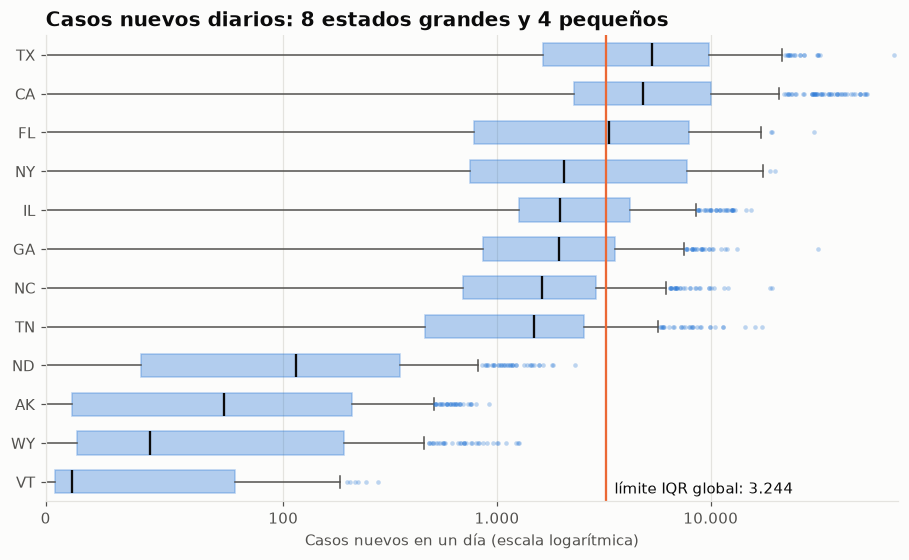

% de días por encima del límite global:
estado
TX    67
CA    65
FL    51
NY    44
IL    30
GA    31
NC    22
TN    20
ND     0
AK     0
WY     0
VT     0


In [3]:
casos_global = limites_iqr(datos["casos_nuevos"])[1]
grandes = datos.groupby("estado")["casos_nuevos"].median().nlargest(8).index
pequenos = ["ND", "AK", "WY", "VT"]   # cuatro de los estados menos poblados
orden = list(grandes) + pequenos

fig, ax = plt.subplots(figsize=(10, 5.5))
cajas = [datos.loc[datos["estado"] == e, "casos_nuevos"].dropna() for e in orden]
ax.boxplot(cajas[::-1], orientation="horizontal", tick_labels=orden[::-1], widths=0.6, patch_artist=True,
           boxprops=dict(facecolor=AZUL, color=AZUL, alpha=0.35),
           medianprops=dict(color=TEXTO, linewidth=1.5),
           whiskerprops=dict(color=TEXTO_SUAVE), capprops=dict(color=TEXTO_SUAVE),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.3))
ax.axvline(casos_global, color=NARANJA, linewidth=1.5)
ax.text(casos_global + 300, 0.7, f"límite IQR global: {formato_miles(casos_global)}", color=TEXTO)
ax.set_xscale("symlog", linthresh=100)
ax.set_xlim(left=0)
ax.xaxis.set_major_formatter(miles)
ax.set_title("Casos nuevos diarios: 8 estados grandes y 4 pequeños")
ax.set_xlabel("Casos nuevos en un día (escala logarítmica)")
ax.grid(axis="y", visible=False)
plt.show()

sobre_global = (datos["casos_nuevos"] > casos_global).groupby(datos["estado"]).mean().mul(100).round(0)
print("% de días por encima del límite global:")
print(sobre_global.loc[orden].astype(int).to_string())

El IQR global **no sirve aquí**: marca el 11 % de las filas, casi todas de Texas, California, Florida o Nueva
York. En Texas y California, dos de cada tres días superan el límite global; en los cuatro estados pequeños, ninguno.
El límite no detecta días raros, sino **estados grandes**. (El eje está en escala logarítmica porque los estados se
mueven entre decenas y decenas de miles de casos, y en escala lineal los pequeños ni se verían).

**Decisión:** estos "atípicos" globales **se quedan**. No son errores, son población. La forma correcta de
compararlos es dividir por habitantes (issue #6, nivel avanzado).

## 2. Segundo intento: el IQR dentro de cada estado

Si calculamos los límites con los datos de cada estado, cada uno se compara consigo mismo.

In [4]:
por_estado = {}
for columna in VARIABLES:
    limite = datos.groupby("estado")[columna].transform(lambda s: limites_iqr(s)[1])
    por_estado[columna] = datos[columna] > limite

pd.DataFrame({VARIABLES[c]: {"días-estado atípicos": int(m.sum()), "% de filas": round(m.mean() * 100, 1)}
              for c, m in por_estado.items()}).T

,días-estado atípicos,% de filas
Casos nuevos,1489.0,7.2
Muertes nuevas,1496.0,7.2
Hospitalizados nuevos,815.0,3.9


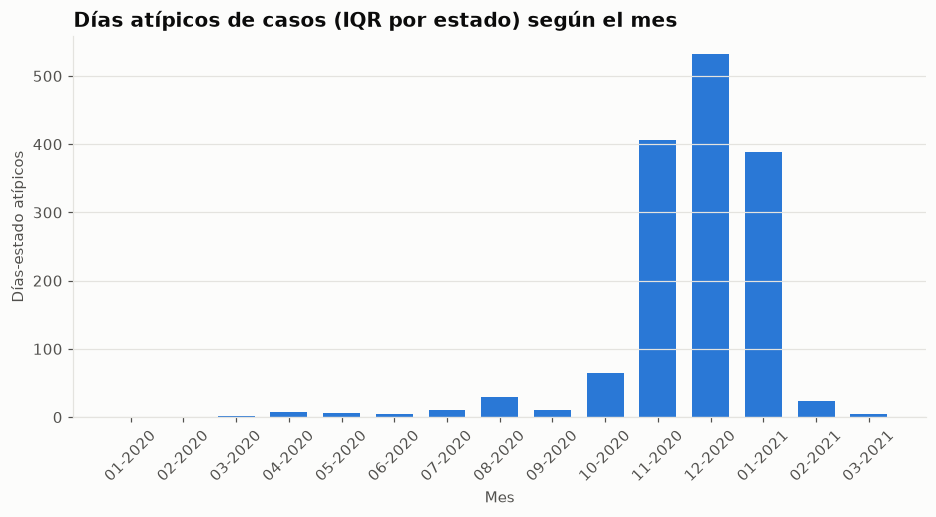

Atípicos entre noviembre de 2020 y enero de 2021: 89%


In [5]:
meses = datos.loc[por_estado["casos_nuevos"], "fecha"].dt.to_period("M").value_counts().sort_index()
meses = meses.reindex(pd.period_range(datos["fecha"].min(), datos["fecha"].max(), freq="M"), fill_value=0)

fig, ax = plt.subplots()
ax.bar(meses.index.strftime("%m-%Y"), meses.values, color=AZUL, width=0.7)
ax.set_title("Días atípicos de casos (IQR por estado) según el mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Días-estado atípicos")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
plt.show()

invierno = meses.loc["2020-11":"2021-01"].sum() / meses.sum()
print(f"Atípicos entre noviembre de 2020 y enero de 2021: {invierno:.0%}")

Unos 1.500 días en casos y en muertes, y **casi 9 de cada 10 caen entre noviembre de 2020 y enero de 2021**:
la ola de invierno. Son
los peores días de cada estado, no errores. Un valor puede ser "atípico" respecto al resto del año y a la vez
ser **el dato más importante del análisis**.

**Decisión:** también **se quedan**. Eliminarlos borraría justo el pico de la pandemia.

## 3. Lo que sí es un problema: picos aislados (atrasos de notificación)

Hay otro tipo de atípico: un día que multiplica por 10 o por 40 a los días de alrededor. Una ola no sube así de
un día para otro y baja al siguiente; un estado que **vuelca de golpe registros atrasados**, sí.

Criterio para marcar un día como **atraso**, dentro de su estado:

1. es atípico por el IQR de ese estado (apartado 2),
2. vale **5 veces o más la media de los 14 días de alrededor** (7 antes y 7 después, sin contar el propio día),
3. supera 20, para no marcar saltos de 1 a 6 en territorios pequeños.

La condición 2 es la clave: un pico de ola tiene vecinos altos; un atraso, no.

In [6]:
atrasos_manual = {}
for columna in VARIABLES:
    vecinos = datos.groupby("estado")[columna].transform(media_vecinos)
    atrasos_manual[columna] = por_estado[columna] & (datos[columna] >= 5 * vecinos) & (datos[columna] >= 20)

# La función marcar_atrasos de src/limpieza.py hace lo mismo; comprobamos que coincide.
datos = marcar_atrasos(datos)
for columna, marca in COLUMNAS_ATRASO.items():
    assert datos[marca].equals(atrasos_manual[columna])

pd.DataFrame({
    VARIABLES[c]: {
        "días marcados": int(datos[m].sum()),
        "estados afectados": datos.loc[datos[m], "estado"].nunique(),
        "% del total de la variable": round(datos.loc[datos[m], c].sum() / datos[c].sum() * 100, 1),
    } for c, m in COLUMNAS_ATRASO.items()
}).T

,días marcados,estados afectados,% del total de la variable
Casos nuevos,8.0,6.0,0.4
Muertes nuevas,58.0,19.0,2.0
Hospitalizados nuevos,117.0,26.0,11.6


In [7]:
datos.loc[datos["atraso_muertes"]].nlargest(8, "muertes_nuevas")[["fecha", "estado", "muertes_nuevas"]]

,fecha,estado,muertes_nuevas
14421,2021-02-12,OH,2559.0
6616,2021-02-04,IN,1546.0
4320,2020-11-03,GA,480.0
14442,2021-03-05,OH,467.0
9964,2021-02-02,MO,340.0
9973,2021-02-11,MO,270.0
9936,2021-01-05,MO,263.0
5502,2021-01-31,IA,250.0


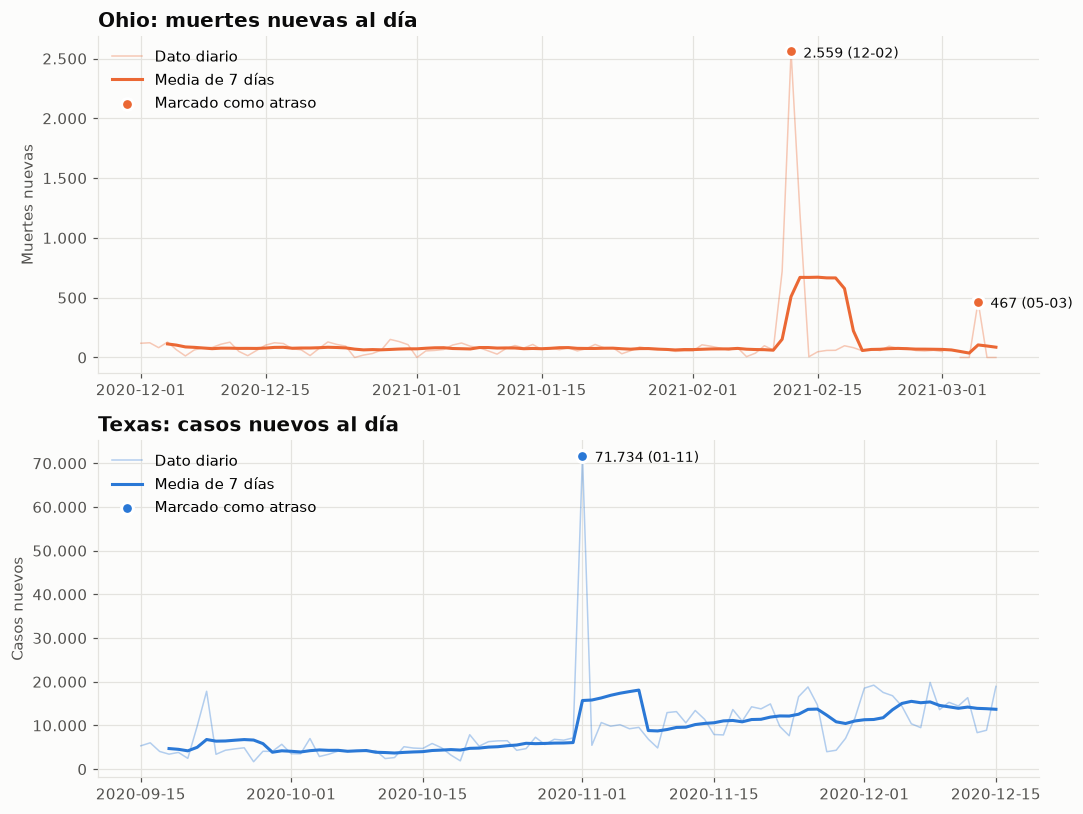

In [8]:
def dibujar_atraso(ax, estado, columna, color, titulo, desde, hasta):
    serie = datos[(datos["estado"] == estado) & datos["fecha"].between(desde, hasta)].set_index("fecha")
    marca = COLUMNAS_ATRASO[columna]
    ax.plot(serie.index, serie[columna], color=color, alpha=0.35, linewidth=1, label="Dato diario")
    ax.plot(serie.index, serie[columna].rolling(7, min_periods=4).mean(), color=color, label="Media de 7 días")
    picos = serie[serie[marca]]
    ax.scatter(picos.index, picos[columna], s=60, color=color, edgecolors="white", linewidths=2, zorder=3,
               label="Marcado como atraso")
    for fecha, valor in picos[columna].items():
        ax.annotate(f"{formato_miles(valor)} ({fecha:%d-%m})", xy=(fecha, valor), xytext=(8, -4),
                    textcoords="offset points", color=TEXTO, fontsize=9)
    ax.set_title(titulo)
    ax.yaxis.set_major_formatter(miles)
    ax.legend(loc="upper left")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.5))
dibujar_atraso(ax1, "OH", "muertes_nuevas", NARANJA, "Ohio: muertes nuevas al día", "2020-12-01", "2021-03-07")
ax1.set_ylabel("Muertes nuevas")
dibujar_atraso(ax2, "TX", "casos_nuevos", AZUL, "Texas: casos nuevos al día", "2020-09-15", "2020-12-15")
ax2.set_ylabel("Casos nuevos")
plt.tight_layout()
plt.show()

Los dos gráficos muestran lo mismo: un punto que se dispara muy por encima de su media de 7 días y vuelve
al nivel normal al día siguiente.

- **Ohio** sumó más de 2.500 muertes el 12-02-2021, cuando su media diaria estaba por debajo de 100: un volcado
  de certificados de defunción de meses anteriores.
- **Texas** sumó casi 72.000 casos el 01-11-2020, unas diez veces lo habitual: resultados de pruebas acumulados
  y publicados de golpe.

Solo hay 8 atrasos en casos (el 0,4 % de todos los casos) y 58 en muertes (el 2 %).

**Limitación del criterio:** cuando el volcado dura varios días seguidos, los picos se tapan entre sí. Ohio
también sumó 721 muertes el 11-02 y 1.204 el 13-02, pero esos días no salen marcados: al compararlos con sus
vecinos, la media ya incluye el 2.559 del día 12. El criterio detecta los volcados más claros, no todos. Por eso,
en las series temporales seguimos usando la media de 7 días, que amortigua también los que se escapan.

### 3.1 El caso especial de los hospitalizados nuevos

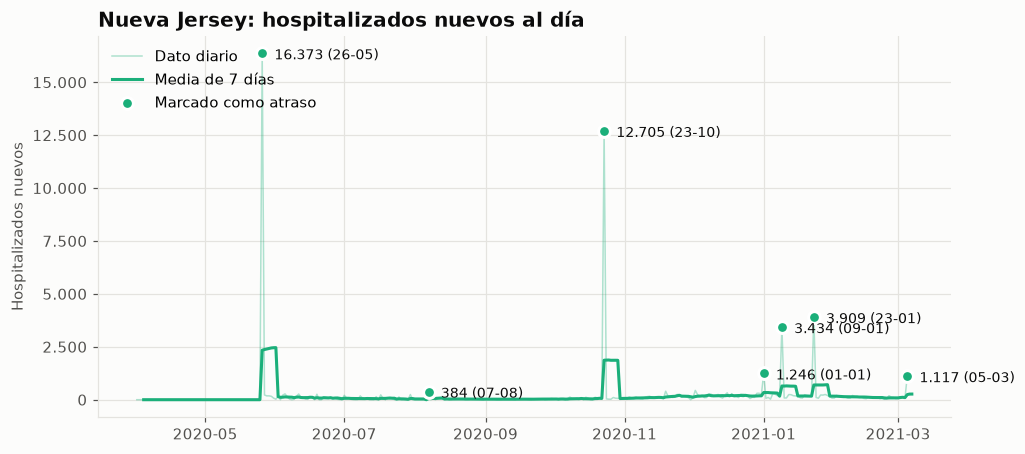

Atrasos de hospitalizados el primer día que el estado informa: 12 de 117


In [9]:
fig, ax = plt.subplots()
dibujar_atraso(ax, "NJ", "hospitalizados_nuevos", VERDE, "Nueva Jersey: hospitalizados nuevos al día",
               "2020-04-01", "2021-03-07")
ax.set_ylabel("Hospitalizados nuevos")
plt.show()

primer_dato = (datos[datos["hospitalizados_nuevos"] > 0].groupby("estado")["fecha"].min())
atrasos_h = datos[datos["atraso_hospitalizados"]]
en_primer_dia = (atrasos_h["fecha"].values == primer_dato.reindex(atrasos_h["estado"]).values).sum()
print(f"Atrasos de hospitalizados el primer día que el estado informa: {en_primer_dia} de {len(atrasos_h)}")

En hospitalizados los atrasos pesan **el 12 % del total**, y 12 de ellos caen justo el primer día que un estado
empieza a informar: ese día vuelca todo el acumulado anterior como si fuera "nuevo". Nueva Jersey, además, cambió
la definición varias veces.

**Decisión:** `hospitalizados_nuevos` **no es fiable** y no la usamos para sacar conclusiones. Para hablar de
presión hospitalaria usamos `hospitalizados_actuales` (personas ingresadas ese día), que no es un incremento y no
arrastra estos saltos.

## 4. Qué hacemos con cada tipo de atípico

| Tipo | Ejemplo | Cuántos | Decisión | Por qué |
|---|---|---|---|---|
| Atípico por IQR global | Cualquier día normal de California | ~11 % de las filas | **Se queda** | Refleja el tamaño del estado, no un error. Se corrige normalizando por población. |
| Atípico por IQR del estado | Enero de 2021 en casi todos los estados | ~1.500 por variable | **Se queda** | Son los picos reales de las olas: lo que queremos analizar. |
| Atraso en casos o muertes | Ohio 12-02-2021, Texas 01-11-2020 | 8 y 58 | **Se queda el valor y se marca** (`atraso_casos`, `atraso_muertes`) | Los casos y muertes existieron, solo se publicaron tarde: borrarlos dejaría los totales cortos. En las series temporales usamos la media de 7 días, y en los análisis día a día podemos excluirlos con la marca. |
| Atraso en hospitalizados nuevos | Nueva Jersey 26-05-2020 | 117 | **Se marca y la variable no se usa** | Pesan el 12 % del total y muchos son el primer día de datos. Usamos `hospitalizados_actuales`. |

No **imputamos** ningún atípico: no sabemos cómo se repartían los registros atrasados entre los días anteriores,
y repartirlos a ojo sería inventar datos.

## 5. Repaso de todas las decisiones de limpieza

Reunimos aquí las decisiones del notebook 01 y de este, cada una con las alternativas que descartamos.

In [10]:
def huecos_interiores(serie):
    validos = serie.notna().to_numpy()
    if not validos.any():
        return 0
    inicio, fin = validos.argmax(), len(validos) - validos[::-1].argmax()
    return int((~validos[inicio:fin]).sum())

pd.DataFrame({
    columna: {
        "% nulos": round(datos[columna].isna().mean() * 100, 1),
        "nulos en medio de la serie": datos.groupby("estado")[columna].apply(huecos_interiores).sum(),
    } for columna in ["casos_acum", "muertes_acum", "tests_acum", "hospitalizados_actuales"]
}).T

,% nulos,nulos en medio de la serie
casos_acum,0.9,0.0
muertes_acum,4.1,0.0
tests_acum,0.8,0.0
hospitalizados_actuales,16.6,117.0


Esta tabla respalda la decisión de **no imputar**: en los acumulados, todos los nulos están al principio de
cada serie (cero huecos en medio). Son días anteriores a que el estado empezara a informar.

| Decisión | Alternativas descartadas | Por qué |
|---|---|---|
| Descartar 41 de 56 columnas | Imputar las columnas con muchos nulos | 26 superan el 50 % de nulos y cada estado las medía con una unidad distinta; imputarlas sería inventar más de la mitad. Las demás eran constantes, copias o metadatos. |
| No imputar los acumulados (`casos_acum`, `muertes_acum`, `tests_acum`) | Media, mediana, 0, rellenar hacia delante | Los nulos son "aún no se informaba", no "falta un dato". La media o la mediana de un acumulado no tienen sentido (crece cada día) y un 0 falsearía el inicio. |
| No imputar `hospitalizados_actuales` | Interpolar los 117 huecos interiores | Son el 0,6 % de las filas y no cambian las tendencias. Los nulos grandes (primavera de 2020) no se pueden reconstruir. Lo tenemos en cuenta al interpretar esa época. |
| Incrementos negativos → `NaN` + marca `es_correccion` | Poner 0, borrar la fila, restarlos de días anteriores | No sabemos a qué días corresponde la corrección. Un 0 sería un dato falso y borrar la fila perdería sus otras columnas, que son válidas. |
| Mantener los territorios y marcarlos (`es_territorio`) | Eliminarlos | Son población de EE. UU. con datos válidos; la marca permite separarlos si hace falta. |
| Mantener los atípicos de ola | Eliminarlos o recortarlos | Son el fenómeno que estudiamos. |
| Mantener los atrasos y marcarlos | Eliminarlos o repartirlos | Ver apartado 4. |
| No usar `hospitalizados_nuevos` | Usarla quitando los atrasos | El 12 % del total está en saltos de definición o de inicio de serie. |
| 59 filas con más positivos que tests: se dejan | Corregirlas | Vienen de unidades distintas (personas frente a muestras); se estudian en la issue #7. |

## 6. Guardar los datos con las marcas nuevas

In [11]:
RUTA_LIMPIOS.parent.mkdir(parents=True, exist_ok=True)
datos.to_csv(RUTA_LIMPIOS, index=False)
print("Guardado:", RUTA_LIMPIOS.relative_to(RAIZ), datos.shape)
print("Columnas nuevas:", ", ".join(COLUMNAS_ATRASO.values()))

Guardado: data\processed\covid_estados_limpio.csv (20780, 20)
Columnas nuevas: atraso_casos, atraso_muertes, atraso_hospitalizados


## Conclusiones

- Con datos de estados de tamaños tan distintos, **el IQR global no detecta días raros, sino estados grandes**.
  Hay que calcularlo dentro de cada estado.
- La mayoría de los atípicos por estado son **los picos reales de la ola de invierno** y se quedan.
- Los atípicos problemáticos son los **atrasos de notificación**: picos aislados que multiplican por 5 o más a
  sus vecinos. Hay pocos en casos y muertes (se quedan, marcados) y muchos en hospitalizados nuevos (la variable
  se descarta).
- Todas las decisiones de limpieza tienen ya su justificación, y los datos limpios incluyen las marcas para
  los siguientes análisis.